### Fähre füllen – Lösung Schritt für Schritt

*33. Bundeswettbewerb Informatik (2014), 1. Runde, Junioraufgabe 1*

Von Oberdellendorf verkehrt eine Autofähre über die Wesau nach Niederdellendorf. Die nächste Brücke ist weit entfernt; deshalb
ist die Fähre sehr beliebt, und an der Anlegestelle ist die Warteschlange lang. Da ist es wichtig, so viele Autos wie möglich
auf der Fähre unterzubringen.

Der Fährbegleiter kann die Fahrzeuge – Pkws, Pkws mit Anhängern, Kleinlaster usw. – bei der Auffahrt jeweils in eine der drei,
jeweils 20 m langen Parkbahnen der Fähre dirigieren. Er weist wiederholt das Fahrzeug am Kopf der Warteschlange einer Parkbahn
zu und kennt dabei die Länge dieses Fahrzeuges, aber nicht die der nachfolgenden Fahrzeuge. Zwischen zwei aufeinanderfolgenden
Fahrzeugen auf einer Parkbahn wird ein Abstand von 30 cm frei gelassen. Sobald das Fahrzeug am Kopf der Warteschlange nicht
mehr untergebracht werden kann, legt die Fähre ab.

#### Junioraufgabe 1

1. Finde zwei einfache Strategien A und B, die der Fährbegleiter bei der Zuweisung der Fahrzeuge zu den Parkbahnen anwenden
   könnte. Wähle die Strategien so, dass bei manchen Folgen von wartenden Fahrzeugen die Strategie A und bei manchen anderen
   die Strategie B mehr Fahrzeuge auf der Fähre unterbringt.
2. Schreibe ein Programm, das eine Folge von Längen von wartenden Fahrzeugen einliest und übersichtlich ausgibt, wie die
   Strategien A und B mit dieser Eingabe die Fähre beladen.
3. Wende dein Programm auf die folgenden drei Beispiele an. Angegeben sind jeweils die Längen einiger Fahrzeuge (in Metern) in
   der Reihenfolge, in der sie in der Warteschlange stehen:
   - 6,96; 5,06; 3,77; 3,95; 3,91; 3,54; 4,26; 4,03; 5,43; 4,04; 4,43; 4,12; 2,78
   - 4,14; 3,63; 3,92; 7,95; 5,23; 3,30; 4,86; 15,06
   - 5,23; 4,41; 3,33; 13,13; 9,12; 4,38; 6,34; 5,37; 4,11; 3,74; 10,62

   Belege mit diesen oder anderen Beispielen, dass manchmal Strategie A und manchmal Strategie B besser abschneidet.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `faehre-beispiel1.txt` bis `faehre-beispiel3.txt`: die drei Beispiele von oben, je eine Zeile mit den Längen (Dezimalpunkt, durch Leerzeichen getrennt).

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Online-Algorithmus:** Der Fährbegleiter muss für jedes Fahrzeug **sofort** entscheiden, ohne die späteren zu kennen. Darum gibt es keine Strategie, die immer die beste Beladung findet. Verschiedene Strategien sind bei verschiedenen Folgen besser.
- **Strategien als einfache Regeln:** Jede Strategie ist eine Regel, wie man die Bahn für das nächste Fahrzeug auswählt. Wir programmieren zwei davon:
  - **A „Der Reihe nach“ (First Fit):** die erste Bahn, in die das Fahrzeug noch passt.
  - **B „Balanciert“:** die Bahn mit dem meisten freien Platz.
- **Rechnen mit Längen:** Zwischen zwei Fahrzeugen sind 30 cm Abstand, aber nicht vor dem ersten und nicht nach dem letzten. Eine Bahn mit `k` Fahrzeugen belegt also die Summe der Längen plus `(k − 1) · 30 cm`.
- **Mit ganzen Zahlen rechnen:** Kommazahlen sind ungenau (`0.1 + 0.2` ist nicht genau `0.3`). Wir rechnen deshalb in **Zentimetern** mit ganzen Zahlen (`int(round(länge * 100))`).
- **Ausgabe übersichtlich gestalten:** Je Bahn eine Zeile mit den Fahrzeugen in Reihenfolge, freiem oder belegtem Platz und der Nummer in der Warteschlange.

**Nützliche Funktionen und Bibliotheken**
- `round`, `int`, `min`/`max` mit Schlüssel (hier einfache Schleifen), `sum`, f-Strings mit Formaten wie `{x:.2f}`
- Für die Zeichnung: `matplotlib.pyplot` (optional)

## Die Idee

Die Fähre hat drei Bahnen von je 2000 cm. In einer Bahn mit den Längen `l1, l2, ..., lk` (in cm) ist der belegte Platz `l1 + ... + lk + 30 · (k − 1)`. Ein neues Fahrzeug der Länge `l` passt in die Bahn, wenn

- die Bahn leer ist und `l ≤ 2000`, oder
- die Bahn nicht leer ist und `belegt + 30 + l ≤ 2000`.

**Strategie A, „der Reihe nach“:** Für jedes Fahrzeug probieren wir Bahn 1, dann Bahn 2, dann Bahn 3 und nehmen die erste, in die es passt.
Passt es in keine, legt die Fähre ab.

**Strategie B, „balanciert“:** Für jedes Fahrzeug nehmen wir die Bahn mit dem **wenigsten belegten Platz** (bei Gleichstand die mit der kleinsten Nummer). Passt es dort nicht, legt die Fähre ab.
Passt es in der am wenigsten belegten Bahn nicht, dann auch in keiner anderen.

Beide Strategien sind sehr einfach und gut zu verstehen. A packt eine Bahn nach der anderen voll und lässt so die letzte Bahn lange frei (gut für spät kommende lange Fahrzeuge).
B hält die Bahnen gleichmäßig leer (gut, wenn viele mittellange Fahrzeuge kommen).

## Schritt 1: Die Längen einlesen

Die Datei hat eine Zeile mit Längen in Metern (Dezimalpunkt). Wir lesen sie, zerlegen sie mit `split()`, wandeln jede Zahl mit `float` um und dann in ganze Zentimeter: `int(round(meter * 100))`.
Das Runden mit `round` ist wichtig, denn `float('4.14') * 100` ergibt `413.99999999999994`, und `int(...)` allein würde auf 413 abschneiden.

In [ ]:
def lies_laengen(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        woerter = f.read().split()
    laengen = []
    for wort in woerter:
        laengen.append(int(round(float(wort) * 100)))
    return laengen


print(float('4.14') * 100, int(float('4.14') * 100), int(round(float('4.14') * 100)))
laengen = lies_laengen('beispieldaten/faehre-beispiel2.txt')
print(laengen)

413.99999999999994 413 414
[414, 363, 392, 795, 523, 330, 486, 1506]


## Schritt 2: Passt ein Fahrzeug in eine Bahn?

Eine Bahn ist eine Liste von Fahrzeugen. Jedes Fahrzeug speichern wir als `[länge, nummer]`, damit wir in der Ausgabe auch seine Nummer in der Warteschlange angeben können (Fahrzeuge gleicher Länge sind sonst nicht zu unterscheiden).
`belegt(bahn)` berechnet den belegten Platz mit den Abständen, `passt(bahn, laenge)` prüft nach der Regel aus der Idee.

In [ ]:
BAHNLAENGE = 2000                      # 20 m in cm
ABSTAND = 30                           # 30 cm zwischen zwei Fahrzeugen


def belegt(bahn):
    summe = 0
    for laenge, nummer in bahn:
        summe = summe + laenge
    if len(bahn) > 1:
        summe = summe + ABSTAND * (len(bahn) - 1)
    return summe


def passt(bahn, laenge):
    if len(bahn) == 0:
        return laenge <= BAHNLAENGE
    return belegt(bahn) + ABSTAND + laenge <= BAHNLAENGE


bahn = [[1000, 1], [500, 2]]
print('belegt:', belegt(bahn), ' passt 450?', passt(bahn, 450), ' passt 470?', passt(bahn, 470))
print('leere Bahn, 2000 cm:', passt([], 2000), ' 2001 cm:', passt([], 2001))

belegt: 1530  passt 450? False  passt 470? False
leere Bahn, 2000 cm: True  2001 cm: False


## Schritt 3: Die beiden Strategien

Beide Strategien geben die drei Bahnen zurück, wenn die Fähre ablegt. Das Ablegen heißt: Bei dem Fahrzeug, das nicht mehr untergebracht werden kann, brechen wir die Schleife ab (`break`).

- **A:** Für jedes Fahrzeug gehen wir die Bahnen 0, 1, 2 der Reihe nach durch und nehmen die erste, in die es passt. Haben wir keine gefunden (`gefunden` bleibt `False`), legt die Fähre ab.
- **B:** Wir suchen die Bahn mit dem kleinsten belegten Platz. Die Schleife `for k in range(1, 3)` ersetzt `beste`, wenn eine Bahn **strikt** weniger belegt ist (deshalb gewinnt bei Gleichstand die kleinere Nummer).

In [ ]:
def strategie_a(laengen):
    bahnen = [[], [], []]
    for nummer in range(len(laengen)):
        laenge = laengen[nummer]
        gefunden = False
        for bahn in bahnen:
            if not gefunden and passt(bahn, laenge):
                bahn.append([laenge, nummer + 1])
                gefunden = True
        if not gefunden:
            break                       # das Fahrzeug passt nirgends: die Fähre legt ab
    return bahnen


def strategie_b(laengen):
    bahnen = [[], [], []]
    for nummer in range(len(laengen)):
        laenge = laengen[nummer]
        beste = 0
        for k in range(1, 3):
            if belegt(bahnen[k]) < belegt(bahnen[beste]):
                beste = k
        if passt(bahnen[beste], laenge):
            bahnen[beste].append([laenge, nummer + 1])
        else:
            break
    return bahnen


def anzahl(bahnen):
    summe = 0
    for bahn in bahnen:
        summe = summe + len(bahn)
    return summe


for dateiname in ['beispieldaten/faehre-beispiel1.txt', 'beispieldaten/faehre-beispiel2.txt', 'beispieldaten/faehre-beispiel3.txt']:
    laengen = lies_laengen(dateiname)
    print(dateiname, ':', len(laengen), 'Fahrzeuge, A bringt', anzahl(strategie_a(laengen)), 'unter, B bringt', anzahl(strategie_b(laengen)), 'unter')

beispieldaten/faehre-beispiel1.txt : 13 Fahrzeuge, A bringt 11 unter, B bringt 11 unter
beispieldaten/faehre-beispiel2.txt : 8 Fahrzeuge, A bringt 8 unter, B bringt 7 unter
beispieldaten/faehre-beispiel3.txt : 11 Fahrzeuge, A bringt 9 unter, B bringt 8 unter


## Schritt 4: Übersichtliche Ausgabe

`zeige(bahnen)` schreibt für jede Bahn eine Zeile: Die Fahrzeuge der Bahn in der Reihenfolge, in der sie aufgefahren sind (links zuerst, das ist die Rückseite der Fähre, `|` markiert den Abstand), jeweils mit
Länge in Metern und der Nummer in der Warteschlange in eckigen Klammern. Am Ende der Zeile steht der belegte Platz. `{x / 100:.2f}` schreibt einen Zentimeterwert als Meter mit zwei Nachkommastellen.

In [ ]:
def zeige(bahnen, laengen_gesamt):
    for k in range(3):
        fahrzeuge = []
        for laenge, nummer in bahnen[k]:
            fahrzeuge.append(f'{laenge / 100:.2f}[{nummer}]')
        print(f'  P{k + 1}: Rückseite | {" | ".join(fahrzeuge)} | Auffahrt   belegt: {belegt(bahnen[k]) / 100:.2f} m')
    print(f'  Untergebracht: {anzahl(bahnen)} von {laengen_gesamt} Fahrzeugen')


def vergleiche(laengen, titel):
    print(titel, f'({len(laengen)} Fahrzeuge)')
    print(' Strategie A (der Reihe nach):')
    zeige(strategie_a(laengen), len(laengen))
    print(' Strategie B (balanciert):')
    zeige(strategie_b(laengen), len(laengen))
    print()


vergleiche(lies_laengen('beispieldaten/faehre-beispiel1.txt'), 'Beispiel 1')

Beispiel 1 (13 Fahrzeuge)
 Strategie A (der Reihe nach):
  P1: Rückseite | 6.96[1] | 5.06[2] | 3.77[3] | Auffahrt   belegt: 16.39 m
  P2: Rückseite | 3.95[4] | 3.91[5] | 3.54[6] | 4.26[7] | Auffahrt   belegt: 16.56 m
  P3: Rückseite | 4.03[8] | 5.43[9] | 4.04[10] | 4.43[11] | Auffahrt   belegt: 18.83 m
  Untergebracht: 11 von 13 Fahrzeugen
 Strategie B (balanciert):
  P1: Rückseite | 6.96[1] | 3.54[6] | 5.43[9] | Auffahrt   belegt: 16.53 m
  P2: Rückseite | 5.06[2] | 3.91[5] | 4.03[8] | 4.43[11] | Auffahrt   belegt: 18.33 m
  P3: Rückseite | 3.77[3] | 3.95[4] | 4.26[7] | 4.04[10] | Auffahrt   belegt: 16.92 m
  Untergebracht: 11 von 13 Fahrzeugen



## Schritt 5: Alle Beispiele

In [ ]:
vergleiche(lies_laengen('beispieldaten/faehre-beispiel2.txt'), 'Beispiel 2')
vergleiche(lies_laengen('beispieldaten/faehre-beispiel3.txt'), 'Beispiel 3')

Beispiel 2 (8 Fahrzeuge)
 Strategie A (der Reihe nach):
  P1: Rückseite | 4.14[1] | 3.63[2] | 3.92[3] | 5.23[5] | Auffahrt   belegt: 17.82 m
  P2: Rückseite | 7.95[4] | 3.30[6] | 4.86[7] | Auffahrt   belegt: 16.71 m
  P3: Rückseite | 15.06[8] | Auffahrt   belegt: 15.06 m
  Untergebracht: 8 von 8 Fahrzeugen
 Strategie B (balanciert):
  P1: Rückseite | 4.14[1] | 3.30[6] | 4.86[7] | Auffahrt   belegt: 12.90 m
  P2: Rückseite | 3.63[2] | 7.95[4] | Auffahrt   belegt: 11.88 m
  P3: Rückseite | 3.92[3] | 5.23[5] | Auffahrt   belegt: 9.45 m
  Untergebracht: 7 von 8 Fahrzeugen

Beispiel 3 (11 Fahrzeuge)
 Strategie A (der Reihe nach):
  P1: Rückseite | 5.23[1] | 4.41[2] | 3.33[3] | 4.38[6] | Auffahrt   belegt: 18.25 m
  P2: Rückseite | 13.13[4] | 6.34[7] | Auffahrt   belegt: 19.77 m
  P3: Rückseite | 9.12[5] | 5.37[8] | 4.11[9] | Auffahrt   belegt: 19.20 m
  Untergebracht: 9 von 11 Fahrzeugen
 Strategie B (balanciert):
  P1: Rückseite | 5.23[1] | 4.38[6] | 6.34[7] | Auffahrt   belegt: 16.55 m
  

Diese Ergebnisse stimmen mit den offiziellen Lösungshinweisen überein (dort heißen die Strategien „Der Reihe nach“ und „Balanciert“):

| Beispiel | Fahrzeuge | A (der Reihe nach) | B (balanciert) |
|---|---|---|---|
| 1 | 13 | 11 | 11 |
| 2 | 8 | **8** | 7 |
| 3 | 11 | **9** | 8 |

In Beispiel 2 und 3 ist **A besser**. Der Grund: In Beispiel 2 steht ein langes Fahrzeug (15,06 m) am Ende der Schlange. Strategie A hat die dritte Bahn bis dahin frei gehalten. Bei B sind alle drei Bahnen schon
mindestens 9,45 m belegt, es sind nur noch höchstens 10,55 m frei, und das lange Fahrzeug passt nicht mehr. In Beispiel 1 sind beide gleich gut.

## Ein Beispiel, bei dem B besser ist

Die Aufgabe verlangt auch eine Folge, bei der **B besser** ist als A. Wir suchen eine kleine Warteschlange mit vielen mittellangen Fahrzeugen. Mit den Längen 3, 10, 11, 11 und 9 m passiert Folgendes:

- **A** stellt das erste Fahrzeug (3 m) in Bahn 1 und das zweite (10 m) dazu (13,30 m belegt). Die zwei Fahrzeuge mit 11 m kommen in Bahn 2 und 3. Das letzte (9 m) passt in keine Bahn mehr
  (13,30 + 0,30 + 9 = 22,60 m, 11 + 0,30 + 9 = 20,30 m): Die Fähre legt mit 4 Fahrzeugen ab.
- **B** stellt 3 m in Bahn 1, 10 m in Bahn 2 und 11 m in Bahn 3. Das nächste 11-m-Fahrzeug kommt in die am wenigsten belegte Bahn 1 (3 + 0,30 + 11 = 14,30 m). Das letzte (9 m) kommt in Bahn 2,
  die jetzt am wenigsten belegt ist (10 + 0,30 + 9 = 19,30 m): **alle fünf** Fahrzeuge passen.

In [ ]:
eigenes = [300, 1000, 1100, 1100, 900]          # 3, 10, 11, 11, 9 Meter (in cm)
vergleiche(eigenes, 'Eigenes Beispiel')

Eigenes Beispiel (5 Fahrzeuge)
 Strategie A (der Reihe nach):
  P1: Rückseite | 3.00[1] | 10.00[2] | Auffahrt   belegt: 13.30 m
  P2: Rückseite | 11.00[3] | Auffahrt   belegt: 11.00 m
  P3: Rückseite | 11.00[4] | Auffahrt   belegt: 11.00 m
  Untergebracht: 4 von 5 Fahrzeugen
 Strategie B (balanciert):
  P1: Rückseite | 3.00[1] | 11.00[4] | Auffahrt   belegt: 14.30 m
  P2: Rückseite | 10.00[2] | 9.00[5] | Auffahrt   belegt: 19.30 m
  P3: Rückseite | 11.00[3] | Auffahrt   belegt: 11.00 m
  Untergebracht: 5 von 5 Fahrzeugen



## Für Neugierige: Die Beladung zeichnen

Wir zeichnen für jede Strategie die drei Bahnen als Balken: Jedes Fahrzeug ist ein Stück, das mit seiner Länge und seiner Nummer beschriftet ist. Zwischen den Fahrzeugen bleibt die Lücke von 30 cm.
Die Zeichnung zeigt sofort, wo der Platz verloren geht.

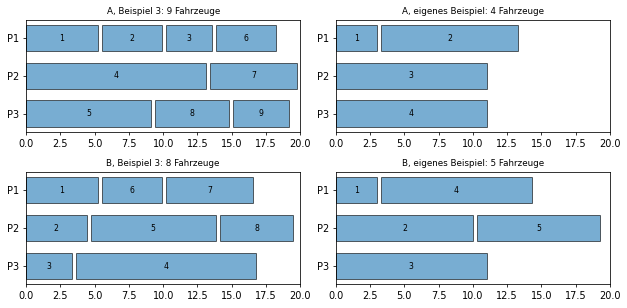

In [ ]:
import matplotlib.pyplot as plt


def zeichne(bahnen, achse, titel):
    for k in range(3):
        links = 0
        for laenge, nummer in bahnen[k]:
            achse.barh(2 - k, laenge / 100, left=links / 100, height=0.7, edgecolor='black', color='tab:blue', alpha=0.6)
            achse.text((links + laenge / 2) / 100, 2 - k, str(nummer), ha='center', va='center', fontsize=8)
            links = links + laenge + ABSTAND
    achse.set_xlim(0, 20)
    achse.set_yticks([0, 1, 2])
    achse.set_yticklabels(['P3', 'P2', 'P1'])
    achse.set_title(f'{titel}: {anzahl(bahnen)} Fahrzeuge', fontsize=9)


bild, achsen = plt.subplots(2, 2, figsize=(9, 4.5))
for spalte, (laengen, name) in enumerate([(lies_laengen('beispieldaten/faehre-beispiel3.txt'), 'Beispiel 3'), (eigenes, 'eigenes Beispiel')]):
    zeichne(strategie_a(laengen), achsen[0][spalte], f'A, {name}')
    zeichne(strategie_b(laengen), achsen[1][spalte], f'B, {name}')
plt.tight_layout()
plt.show()

**Weitere Ideen:** Man kann mehr Strategien entwickeln und vergleichen, zum Beispiel „Bahn 3 bis zuletzt frei halten“, „kurze Fahrzeuge in eine eigene Bahn“ oder „die Bahn wählen, in der am wenigsten Platz übrig bleibt“ (Best Fit).
Zu jeder Strategie gibt es eine Folge, bei der sie schlecht abschneidet, denn der Fährbegleiter kennt die späteren Fahrzeuge nicht. Wer **alle** Fahrzeuge schon kennt, kann beliebig lange probieren.